# Is `REGEX_UNITS_PER_STEP = 512` sound, and what does an ordinary survey pay?

The read-only dialect runs at about 3.2M evaluation steps a second, and `STEP_BUDGET` is 3,000,000, so one step is about
312.5 ns. A regex search is one host call whose work the step count never sees, so `regexWork(source, flags, input)`
(`src/readonly-exec/regex-cost.ts`) prices it first: an upper bound, in units, on the backtracking work of one native V8
search over that input, charged at `REGEX_UNITS_PER_STEP` units a step (`docs/dev/readonly-exec.md`, Halting row
`REGEX_UNITS_PER_STEP`). Counted repeats (`{m,n}` with finite n) are weighted x3 inside the bound.

The constant is sound only if every shape costs at most 312.5 / 512 = 0.61 ns per unit of bound. Four groups are timed:
twenty worst-case shapes, counted repeats at up to 2M characters, ten ordinary surveys, and seeded random patterns that
pass `riskyRegex`, on six adversarial inputs (a search whose bound predicts over about 2 s is skipped, and sub-millisecond
timings are dropped as call overhead).

Re-run: `NB_REFRESH=1 node scripts/nb.mjs run notebooks/readonly/regex-cost.ipynb`, which runs
`node --import tsx notebooks/readonly/regex-bench.mjs` from the repo root.

In [1]:
import json, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import wmlnb

HERE = wmlnb.ROOT / "notebooks" / "readonly"
EXTRACT = HERE / "data" / "regex-cost" / "bench.json"
NS_PER_STEP = 312.5
UNITS_PER_STEP = 512
LIMIT = NS_PER_STEP / UNITS_PER_STEP
STEP_BUDGET = 3_000_000
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

def run_bench():
    out = subprocess.run(["node", "--import", "tsx", "notebooks/readonly/regex-bench.mjs"], cwd=wmlnb.ROOT,
                         capture_output=True, text=True, check=True)
    return json.loads(out.stdout)

data = wmlnb.extract(EXTRACT, run_bench, source={"driver": "notebooks/readonly/regex-bench.mjs", "cmd": "node --import tsx notebooks/readonly/regex-bench.mjs"})
meta = data["meta"]
df = pd.DataFrame(data["rows"])
bad = df[df.ns_per_unit.isna()]
df = df[df.ns_per_unit.notna()].copy()
pd.DataFrame(wmlnb.provenance(EXTRACT))

,extract,sha256,rows,extracted_at,commit,cmd,driver
0,notebooks/readonly/data/regex-cost/bench.json,5aa45853928c3785,2,2026-10-22T06:15:03+00:00,78ceaeee64ac,node --import tsx notebooks/readonly/regex-bench.mjs,notebooks/readonly/regex-bench.mjs


## The machine

Load from other processes inflates ns/unit (the timed search shares the core with them), which makes the derived constant
conservative, never optimistic: a load-free run can only be faster per unit.

In [2]:
pd.Series({
    "node": meta["node"], "v8": meta["v8"], "platform": meta["platform"], "cpu": meta["cpus"], "cpus": meta["cpu_count"],
    "loadavg at start (1/5/15 min)": [round(x, 2) for x in meta["loadavg_start"]],
    "loadavg at end": [round(x, 2) for x in meta["loadavg_end"]],
    "run took (s)": meta["seconds"], "date": meta["date"], "rows": len(df), "rows with an error or no bound": len(bad),
}).to_frame("value")

,value
node,v26.5.0
v8,14.6.202.34-node.24
platform,darwin-arm64
cpu,Apple M4
cpus,10
loadavg at start (1/5/15 min),"[7.0, 5.74, 4.79]"
loadavg at end,"[5.95, 5.61, 4.77]"
run took (s),27
date,2026-10-22T06:14:36.576Z
rows,169


## ns per unit of bound, by group

In [3]:
g = df.groupby("group").ns_per_unit
(pd.DataFrame({"max": g.max(), "p95": g.quantile(0.95), "median": g.median(), "count": g.count()})
   .reindex(["worst", "counted", "ordinary", "fuzz"]).round(3))

,max,p95,median,count
group,,,,
worst,0.438,0.407,0.164,20
counted,0.420,0.394,0.272,6
ordinary,0.314,0.257,0.064,10
fuzz,0.380,0.313,0.076,133


The ten rows closest to (or over) the budget line of 0.61 ns per unit, across all groups.

In [4]:
top = df.sort_values("ns_per_unit", ascending=False).head(10)
top[["group", "pattern", "flags", "method", "n", "ms", "units", "ns_per_unit", "steps"]].assign(
    ms=lambda d: d.ms.round(1), units=lambda d: d.units.map("{:.2e}".format), ns_per_unit=lambda d: d.ns_per_unit.round(3))

,group,pattern,flags,method,n,ms,units,ns_per_unit,steps
13,worst,\w+@,g,match,1000000,5.7,1.30e+07,0.438,25391
21,counted,"(?:\d{0,50}|[ab]{3})?\s*b+",u,replace,2000000,399.4,9.52e+08,0.420,1859376
4,worst,"a{1,5000}b",,match,30000,425.6,1.05e+09,0.405,2050909
137,fuzz,\w?(a)*b,i,replace,3000,20.5,5.40e+07,0.380,105545
122,fuzz,\w?(a)*b,i,replace,3000,20.4,5.40e+07,0.378,105545
123,fuzz,\w?(a)*b,i,replace,3000,20.3,5.40e+07,0.376,105510
80,fuzz,[^b]*\s*b,m,replace,3000,12.2,3.60e+07,0.339,70360
38,fuzz,(a)+?b,i,replace,3000,9.1,2.70e+07,0.336,52741
138,fuzz,\w?(a)*b,i,replace,3000,18.1,5.40e+07,0.335,105510
37,fuzz,(a)+?b,i,replace,3000,9.0,2.70e+07,0.334,52758


## The derived constant

`312.5 / max ns per unit` is the most units a step could be charged for if the slowest measured shape were to just fit
its budget. It is compared with the shipped 512; it prints a verdict and does not raise.

In [5]:
worst_row = df.loc[df.ns_per_unit.idxmax()]
derived = NS_PER_STEP / worst_row.ns_per_unit
print(f"max ns/unit = {worst_row.ns_per_unit:.3f}  ({worst_row.group}: /{worst_row.pattern}/{worst_row["flags"]} on n={worst_row.n}, {worst_row.ms:.1f} ms)")
print(f"derived units per step = floor(312.5 / max) = {int(np.floor(derived))}   shipped = {UNITS_PER_STEP}   limit = {LIMIT:.3f} ns/unit")
print("PASS: 512 is within the measured bound" if derived >= UNITS_PER_STEP else "FAIL: a measured shape costs more than 0.61 ns per unit")
print("headroom (derived / 512): %.2fx" % (derived / UNITS_PER_STEP))

max ns/unit = 0.438  (worst: /\w+@/g on n=1000000, 5.7 ms)
derived units per step = floor(312.5 / max) = 713   shipped = 512   limit = 0.610 ns/unit
PASS: 512 is within the measured bound
headroom (derived / 512): 1.39x


## What an ordinary survey pays

Steps charged are `ceil(units / 512)`; the budget is `STEP_BUDGET` = 3,000,000 steps.

In [6]:
o = df[df.group == "ordinary"].copy()
o["pct_of_budget"] = (o.steps / STEP_BUDGET * 100).round(2)
o[["pattern", "flags", "n", "ms", "units", "steps", "pct_of_budget"]].assign(ms=lambda d: d.ms.round(1), units=lambda d: d.units.map("{:.2e}".format))

,pattern,flags,n,ms,units,steps,pct_of_budget
26,^.*error.*$,gm,1480140,2.3,1.31e+09,2562266,85.41
27,error.*$,m,1480140,0.1,3.29e+07,64220,2.14
28,\w+@\w+\.\w+,g,1014000,3.9,3.46e+08,675341,22.51
29,\d+,g,1014000,0.2,5.07e+06,9903,0.33
30,"\s*,\s*",g,1014000,1.7,1.22e+07,23766,0.79
31,(\w+)\s+\1,g,50000,0.3,2.55e+06,4981,0.17
32,status=(\d+),g,1480140,0.2,2.23e+06,4356,0.15
33,[A-Z][a-z]+,g,1014000,0.4,1.16e+06,2260,0.08
34,^\s+|\s+$,g,1014000,1.3,7.10e+06,13864,0.46
35,"""([^""]*)""",g,1500142,0.6,1.40e+07,27305,0.91


## Bound against time

Each point is one timed search. The line is the budget: ms = units x 0.61e-6, where a point on it spends exactly its
steps' worth of time. Points above it are under-charged.

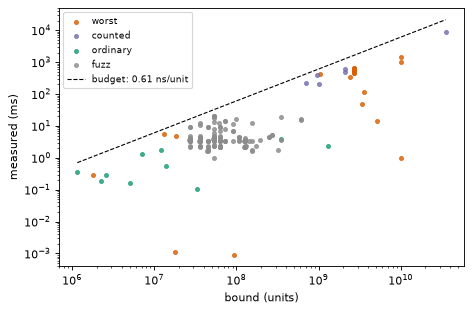

In [7]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=80)
colors = {"worst": "#d95f02", "counted": "#7570b3", "ordinary": "#1b9e77", "fuzz": "#8c8c8c"}
for grp, c in colors.items():
    d = df[(df.group == grp) & (df.ms > 0)]
    ax.scatter(d.units, d.ms, s=12, c=c, label=grp, alpha=0.8)
xs = np.array([df.units.min(), df.units.max()])
ax.plot(xs, xs * LIMIT * 1e-6, "k--", lw=1, label="budget: 0.61 ns/unit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("bound (units)"); ax.set_ylabel("measured (ms)")
ax.legend(fontsize=8); fig.tight_layout()
display(fig)
plt.close(fig)